# Diarization (NeMo Nemotron-3-Diarization)
Who speaks when, for every wav in `data/raw_audios/`. Diarization only: the chunks are made in `05_chunks`.

**Per audio**, in `outputs/diarization/<name>/nemotron/`:
- `<name>.rttm`: the model's turns (`start`, `duration`, `speaker`)
- `stats.json`: speech / overlap / silence, and per speaker: seconds, share of the speech, turns, median turn length
- `timeline.png`: who speaks when

The model needs 16 kHz mono, so a temporary 16 kHz copy is made and deleted after the run.
Audios that already have an RTTM are not run through the model again unless `FORCE = True`. Their stats and timeline are always rebuilt (that takes a moment).

In [11]:
import json
import math
import os
import subprocess
import traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from nemo.collections.asr.models import SortformerEncLabelModel

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
out_root = root / "outputs"
wavs = sorted((root / "data" / "raw_audios").glob("*.wav"))
for i, p in enumerate(wavs):
    print(i, p.name)

0 18-35 yosh bo'lsangiz, shu 8ta darsni eshitishingiz kerak.wav
1 2026-yilda Google'ga ishga kirish XARITASI.wav
2 28-son - GTA VI, Fransiyadagi noroziliklar, Tesla uchar avtomobili va boshqa yangiliklar tahlili.wav
3 29-son - Krinjdan tortib siyosatgacha hafta davomida sodir bo‘lgan voqealar muhokamasi.wav
4 31 - son - Birinçi besoqol, musulmon, tub amerikalik senatorlar. Amerika siyosati kök rangda.wav
5 40 daqiqada yillar davomida yo'qotganimizni qaytaramiz - Maqolim 1-son.wav
6 50 yoshida ham studentlikni tanlaydigan odam bilan suhbat.wav
7 99% odamlar buni eplay olmaydi - Iqtibos podcast #27.wav
8 AQLI PASTlar avlodi (bo'lib qolyapmiz).wav
9 Afsus qilmaslik uchun bugun nima qilish kerak - Hasanxon Yahyo Abdulmajid.wav
10 Chegaralar torayayotganini his qildim - Jamshidxon Ziyoxonov.wav
11 Dasturchilik faoliyatimni yakunlayman! - Azim Pulat Gashtak podkastida.wav
12 Ertaga bankrot bo‘lmaslik uchun hozir nima qilish kerak - Alisher Isayev.wav
13 HOZIRGI YOSHLAR NIMADAN BOSHLASHI KERA

In [12]:
ONLY = None    # None = every audio; or a list of indices from the list above, e.g. [3, 5]
FORCE = False  # True = run the model again even if the audio already has an RTTM

In [13]:
diarizer = SortformerEncLabelModel.from_pretrained("nvidia/Nemotron-3-Diarization")
diarizer.eval()

# streaming settings, in 80 ms frames (340 = ~27 s chunks)
m = diarizer.sortformer_modules
m.chunk_len = 340
m.chunk_right_context = 40
m.fifo_len = 40
m.spkcache_update_period = 300
m.spkcache_len = 264
diarizer._check_streaming_parameters()

[NeMo W 2026-11-24 21:59:13 modelPT:192] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    manifest_filepath: null
    validate_manifest_paths: false
    sample_rate: 16000
    num_spks: 8
    session_len_sec: 105
    soft_targets: false
    batch_size: 42
    shuffle: true
    num_workers: 18
    pin_memory: true
    use_lhotse: false
    subsegment_mode: true
    subsegment_single_chunk_min_len_sec: 45
    subsegment_two_chunks_rate: 0.5
    subsegment_two_chunk_min_len_sec: 22
    subsegment_nspk_bias: 1.5
    subsegment_start_guard_sec: 0.25
    subsegment_min_first_spk_sec: 0.5
    subsegment_splice_silence_sec: 0.1
    
[NeMo W 2026-11-24 21:59:13 modelPT:199] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the

[NeMo I 2026-11-24 21:59:13 save_restore_connector:309] Model SortformerEncLabelModel was successfully restored from /Users/macbook/.cache/huggingface/hub/models--nvidia--Nemotron-3-Diarization/snapshots/52a432672732425e4c19765b9fec9b5810e6f4ba/Nemotron-3-Diarization.nemo.


[NeMo W 2026-11-24 21:59:13 sortformer_modules:241] spkcache_update_period (300) is less than chunk_len (340). The effective update period will be 340.


In [14]:
RES = 100  # stats grid: 10 ms


def diarize(audio_path, tmp_dir):
    """(start, end, speaker) turns. The model gets a temporary 16 kHz mono copy."""
    wav16 = tmp_dir / "audio_16k_mono.tmp.wav"
    try:
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(audio_path),
                        "-ar", "16000", "-ac", "1", "-c:a", "pcm_s16le", str(wav16)], check=True)
        segments = diarizer.diarize(audio=[str(wav16)], batch_size=1)
    finally:
        wav16.unlink(missing_ok=True)
    return sorted((float(s), float(e), spk) for s, e, spk in (line.split() for line in segments[0]))


def write_rttm(turns, name, path):
    file_id = "_".join(name.split())  # RTTM fields are separated by spaces: no spaces in the id
    tmp = path.with_suffix(".rttm.tmp")
    with open(tmp, "w") as f:
        for s, e, spk in turns:
            f.write(f"SPEAKER {file_id} 1 {s:.3f} {e - s:.3f} <NA> <NA> {spk} <NA> <NA>\n")
    os.replace(tmp, path)  # an interrupted run can't leave half an RTTM


def read_rttm(path):
    turns = []
    for line in path.read_text().splitlines():
        p = line.split()  # counted from the end, so an id with spaces still works
        s = float(p[-7])
        turns.append((s, s + float(p[-6]), p[-3]))
    return sorted(turns)


def diarization_stats(audio_name, total_sec, turns):
    speakers = sorted({spk for *_, spk in turns})
    n = math.ceil(total_sec * RES)
    active = np.zeros((len(speakers), n), dtype=bool)
    for s, e, spk in turns:
        active[speakers.index(spk), max(0, round(s * RES)):min(n, round(e * RES))] = True
    count = active.sum(axis=0)
    speech, overlap = int((count >= 1).sum()), int((count >= 2).sum())

    per_speaker = {}
    for k, spk in enumerate(speakers):
        turn_len = [e - s for s, e, x in turns if x == spk]
        per_speaker[spk] = {
            "seconds": round(active[k].sum() / RES, 2),
            "share_of_speech_pct": round(100 * active[k].sum() / max(speech, 1), 1),  # overlap counts for both
            "turns": len(turn_len),
            "median_turn_sec": round(float(np.median(turn_len)), 2),
        }
    return {
        "audio": audio_name,
        "total_seconds": round(total_sec, 2),
        "speakers": len(speakers),
        "turns": len(turns),
        "speech_seconds": round(speech / RES, 2),
        "speech_pct": round(100 * speech / n, 1),
        "overlap_seconds": round(overlap / RES, 2),
        "overlap_pct": round(100 * overlap / n, 1),
        "silence_seconds": round((n - speech) / RES, 2),
        "silence_pct": round(100 * (n - speech) / n, 1),
        "per_speaker": per_speaker,
    }


def plot_timeline(turns, title, path):
    speakers = sorted({spk for *_, spk in turns})
    fig, ax = plt.subplots(figsize=(12, 0.6 * len(speakers) + 1))
    for row, spk in enumerate(speakers):
        ax.broken_barh([(s / 60, (e - s) / 60) for s, e, x in turns if x == spk], (row - 0.4, 0.8))
    ax.set_yticks(range(len(speakers)), speakers)
    ax.set_xlabel("min")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.close(fig)


def process(audio_path):
    name = audio_path.stem
    out_dir = out_root / "diarization" / name / "nemotron"
    out_dir.mkdir(parents=True, exist_ok=True)
    rttm_path = out_dir / f"{name}.rttm"

    if rttm_path.exists() and not FORCE:
        turns = read_rttm(rttm_path)
        print(f"  {len(turns)} saved turns")
    else:
        turns = diarize(audio_path, out_dir)
        write_rttm(turns, name, rttm_path)

    stats = diarization_stats(audio_path.name, sf.info(str(audio_path)).duration, turns)
    (out_dir / "stats.json").write_text(json.dumps(stats, ensure_ascii=False, indent=2), encoding="utf-8")
    plot_timeline(turns, audio_path.name, out_dir / "timeline.png")
    print(f"  {stats['speakers']} speakers, {stats['turns']} turns, speech {stats['speech_pct']}%, "
          f"overlap {stats['overlap_pct']}%, silence {stats['silence_pct']}%")
    return stats

## Run

In [16]:
selected = wavs if ONLY is None else [wavs[i] for i in ONLY]
failed = {}

for n, audio_path in enumerate(selected, 1):
    print(f"[{n}/{len(selected)}] {audio_path.name}")
    try:
        process(audio_path)
    except Exception:
        failed[audio_path.name] = traceback.format_exc()
        print("  FAILED (continuing)")

print(f"\ndone: {len(selected) - len(failed)}, failed: {len(failed)}")
for name, tb in failed.items():
    print("\n" + name + "\n" + tb)

[1/31] 18-35 yosh bo'lsangiz, shu 8ta darsni eshitishingiz kerak.wav
  4006 saved turns
  3 speakers, 4006 turns, speech 77.6%, overlap 3.3%, silence 22.4%
[2/31] 2026-yilda Google'ga ishga kirish XARITASI.wav
  402 saved turns
  7 speakers, 402 turns, speech 91.9%, overlap 0.0%, silence 8.1%
[3/31] 28-son - GTA VI, Fransiyadagi noroziliklar, Tesla uchar avtomobili va boshqa yangiliklar tahlili.wav
  164 saved turns
  8 speakers, 164 turns, speech 93.9%, overlap 0.0%, silence 6.1%
[4/31] 29-son - Krinjdan tortib siyosatgacha hafta davomida sodir bo‘lgan voqealar muhokamasi.wav
  115 saved turns
  8 speakers, 115 turns, speech 93.4%, overlap 0.1%, silence 6.6%
[5/31] 31 - son - Birinçi besoqol, musulmon, tub amerikalik senatorlar. Amerika siyosati kök rangda.wav
  119 saved turns
  8 speakers, 119 turns, speech 93.3%, overlap 0.2%, silence 6.7%
[6/31] 40 daqiqada yillar davomida yo'qotganimizni qaytaramiz - Maqolim 1-son.wav
  930 saved turns
  1 speakers, 930 turns, speech 81.2%, overl

[NeMo W 2026-11-24 22:01:19 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: session_len_sec,subsegment_nspk_bias,num_spks,subsegment_mode,validate_manifest_paths,subsegment_start_guard_sec,subsegment_splice_silence_sec,subsegment_two_chunk_min_len_sec,subsegment_single_chunk_min_len_sec,subsampling_factor,subsegment_two_chunks_rate,subsegment_min_first_spk_sec,soft_label_thres
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-24 22:01:19 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
Post-processing: 100%|██████████| 1/1 [00:00<00:00, 48.47it/s]
Diarizing: 1it [01:47, 107.89s/it]


  3 speakers, 1089 turns, speech 93.2%, overlap 5.8%, silence 6.8%
[20/31] Muvaffaqiyat, Cheklovlar, Baxt, Ichki kuch haqida Ma'rifat Jamal bilan suhbat.wav
[NeMo I 2026-11-24 22:03:08 vad_utils:90] No postprocessing YAML file has been provided. Default postprocessing configurations will be applied.


[NeMo W 2026-11-24 22:03:08 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: session_len_sec,subsegment_nspk_bias,num_spks,subsegment_mode,validate_manifest_paths,subsegment_start_guard_sec,subsegment_splice_silence_sec,subsegment_two_chunk_min_len_sec,subsegment_single_chunk_min_len_sec,subsampling_factor,subsegment_two_chunks_rate,subsegment_min_first_spk_sec,soft_label_thres
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-24 22:03:08 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
Post-processing: 100%|██████████| 1/1 [00:00<00:00, 41.82it/s]
Diarizing: 1it [02:10, 130.67s/it]


  2 speakers, 2444 turns, speech 82.8%, overlap 1.3%, silence 17.2%
[21/31] Nega UYALISHIM Kerak! - Mirshakar Fayzulloyev, Islom Karimov.wav
[NeMo I 2026-11-24 22:05:19 vad_utils:90] No postprocessing YAML file has been provided. Default postprocessing configurations will be applied.


[NeMo W 2026-11-24 22:05:19 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: session_len_sec,subsegment_nspk_bias,num_spks,subsegment_mode,validate_manifest_paths,subsegment_start_guard_sec,subsegment_splice_silence_sec,subsegment_two_chunk_min_len_sec,subsegment_single_chunk_min_len_sec,subsampling_factor,subsegment_two_chunks_rate,subsegment_min_first_spk_sec,soft_label_thres
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-24 22:05:19 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
Post-processing: 100%|██████████| 1/1 [00:00<00:00, 37.84it/s]
Diarizing: 1it [02:12, 132.97s/it]


... (17 outputs left out)


[NeMo W 2026-11-24 22:23:48 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: session_len_sec,subsegment_nspk_bias,num_spks,subsegment_mode,validate_manifest_paths,subsegment_start_guard_sec,subsegment_splice_silence_sec,subsegment_two_chunk_min_len_sec,subsegment_single_chunk_min_len_sec,subsampling_factor,subsegment_two_chunks_rate,subsegment_min_first_spk_sec,soft_label_thres
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-24 22:23:48 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
Post-processing: 100%|██████████| 1/1 [00:00<00:00, 511.75it/s]
Diarizing: 1it [00:01,  1.23s/it]


  3 speakers, 21 turns, speech 90.3%, overlap 5.5%, silence 9.7%
[31/31] hayotingiz isrof bo'lishiga sabab (yo'q, telefon emas).wav
[NeMo I 2026-11-24 22:23:49 vad_utils:90] No postprocessing YAML file has been provided. Default postprocessing configurations will be applied.


[NeMo W 2026-11-24 22:23:49 dataloader:1308] The following configuration keys are ignored by Lhotse dataloader: session_len_sec,subsegment_nspk_bias,num_spks,subsegment_mode,validate_manifest_paths,subsegment_start_guard_sec,subsegment_splice_silence_sec,subsegment_two_chunk_min_len_sec,subsegment_single_chunk_min_len_sec,subsampling_factor,subsegment_two_chunks_rate,subsegment_min_first_spk_sec,soft_label_thres
Diarizing: 0it [00:00, ?it/s][NeMo W 2026-11-24 22:23:49 nemo_logging:365] /Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
      super().__init__(loader)
    
Post-processing: 100%|██████████| 1/1 [00:00<00:00, 271.74it/s]
Diarizing: 1it [00:18, 18.18s/it]

  1 speakers, 22 turns, speech 98.7%, overlap 0.0%, silence 1.3%

done: 31, failed: 0


## Stats of every audio
Read from the `stats.json` files, so it also works after a restart. `main%` = share of the speech of the speaker who talks most.

In [17]:
all_stats = [json.loads(p.read_text(encoding="utf-8"))
             for p in sorted((out_root / "diarization").glob("*/nemotron/stats.json"))]

print(f"{'audio':55} {'min':>6} {'spk':>4} {'turns':>6} {'speech%':>8} {'overlap%':>9} {'silence%':>9} {'main%':>6}")
for s in all_stats:
    main = max((v["share_of_speech_pct"] for v in s["per_speaker"].values()), default=0)
    print(f"{s['audio'][:55]:55} {s['total_seconds'] / 60:6.1f} {s['speakers']:4d} {s['turns']:6d} "
          f"{s['speech_pct']:8.1f} {s['overlap_pct']:9.1f} {s['silence_pct']:9.1f} {main:6.1f}")
total = sum(s["total_seconds"] for s in all_stats)
speech = sum(s["speech_seconds"] for s in all_stats)
print(f"\n{len(all_stats)} audios, {total / 3600:.2f} h, speech {speech / 3600:.2f} h ({100 * speech / max(total, 1):.1f}%)")

audio                                                      min  spk  turns  speech%  overlap%  silence%  main%
18-35 yosh bo'lsangiz, shu 8ta darsni eshitishingiz ker  146.8    3   4006     77.6       3.3      22.4   63.1
2026-yilda Google'ga ishga kirish XARITASI.wav            30.7    7    402     91.9       0.0       8.1   72.4
28-son - GTA VI, Fransiyadagi noroziliklar, Tesla uchar   39.5    8    164     93.9       0.0       6.1   91.5
29-son - Krinjdan tortib siyosatgacha hafta davomida so   40.9    8    115     93.4       0.1       6.6   93.7
31 - son - Birinçi besoqol, musulmon, tub amerikalik se   47.8    8    119     93.3       0.2       6.7   94.8
40 daqiqada yillar davomida yo'qotganimizni qaytaramiz    44.0    1    930     81.2       0.0      18.8  100.0
50 yoshida ham studentlikni tanlaydigan odam bilan suhb  120.0    4   2904     81.4       2.7      18.6   75.3
99% odamlar buni eplay olmaydi - Iqtibos podcast #27.wa   45.3    1    939     78.2       0.0      21.8  100.0
A

## One audio in detail

{
  "audio": "18-35 yosh bo'lsangiz, shu 8ta darsni eshitishingiz kerak.wav",
  "total_seconds": 8806.01,
  "speakers": 3,
  "turns": 4006,
  "speech_seconds": 6834.19,
  "speech_pct": 77.6,
  "overlap_seconds": 291.85,
  "overlap_pct": 3.3,
  "silence_seconds": 1971.82,
  "silence_pct": 22.4,
  "per_speaker": {
    "speaker_0": {
      "seconds": 4312.74,
      "share_of_speech_pct": 63.1,
      "turns": 2278,
      "median_turn_sec": 1.41
    },
    "speaker_1": {
      "seconds": 2805.28,
      "share_of_speech_pct": 41.0,
      "turns": 1714,
      "median_turn_sec": 1.09
    },
    "speaker_2": {
      "seconds": 8.02,
      "share_of_speech_pct": 0.1,
      "turns": 14,
      "median_turn_sec": 0.48
    }
  }
}


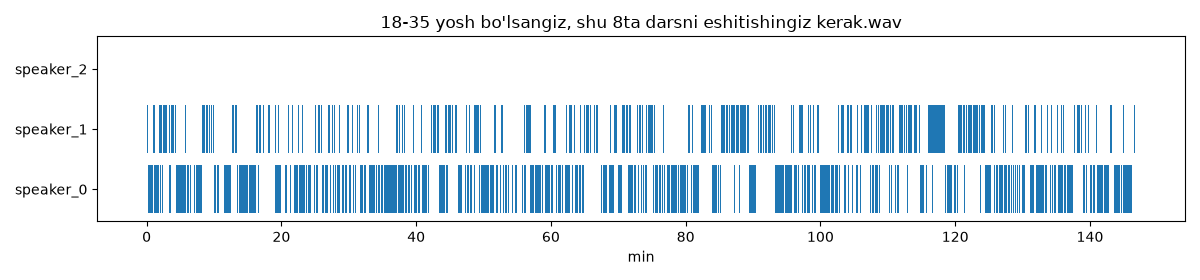

In [18]:
from IPython.display import Image, display

i = 0  # index from the list at the top
out_dir = out_root / "diarization" / wavs[i].stem / "nemotron"
print(json.dumps(json.loads((out_dir / "stats.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=2))
display(Image(str(out_dir / "timeline.png")))